In [1]:
import json
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

with open('api_troll_farm.json') as f:
    datos = json.load(f)

print(len(datos))
print(datos[0])

23
{'account_id': 'TROLL_BOT_1', 'metadata': {'last_ip': '104.28.19.112', 'payment_hash': 'VISA-4455-XXXX-9090'}, 'activity': {'retweets': ['real_user_11', 'TROLL_BOT_1', 'TROLL_BOT_1']}}


## Fase 1: Data Engineering

In [2]:
filas = []

for cuenta in datos:
    origen = cuenta['account_id'].strip().upper()
    if cuenta['activity'] is not None:
        for destino in cuenta['activity']['retweets']:
            destino = destino.strip().upper()
            if origen != destino:
                filas.append([origen, destino, 'Retweet'])\
                    
retweets = pd.DataFrame(filas, columns=['Origen', 'Destino', 'Relacion'])


In [3]:
meta = []
for cuenta in datos:
    if cuenta['metadata'] is not None:
        meta.append([cuenta['account_id'].strip().upper(), cuenta['metadata']['last_ip'], cuenta['metadata']['payment_hash']])

meta = pd.DataFrame(meta, columns=['Usuario', 'IP', 'Tarjeta'])
meta.dropna(subset=['Tarjeta'], inplace=True)
meta = meta.drop_duplicates()
display(meta.head())


,Usuario,IP,Tarjeta
0,TROLL_BOT_1,104.28.19.112,VISA-4455-XXXX-9090
1,REAL_USER_14,189.168.1.196,MC-8573-XXXX-1111
3,TROLL_BOT_5,104.28.19.112,VISA-4455-XXXX-9090
4,REAL_USER_12,189.168.1.51,MC-4432-XXXX-1111
5,REAL_USER_11,189.168.1.231,MC-5554-XXXX-1111


In [4]:
pares = pd.merge(meta, meta, on='Tarjeta')
pares = pares[pares['Usuario_x'] < pares['Usuario_y']]

tarjetas = pd.DataFrame({'Origen': pares['Usuario_x'], 'Destino': pares['Usuario_y'], 'Relacion': 'Misma_Tarjeta'})

In [5]:
df = pd.concat([retweets, tarjetas])
df = df.drop_duplicates()
display(df.head())
print(df['Relacion'].value_counts())

,Origen,Destino,Relacion
0,TROLL_BOT_1,REAL_USER_11,Retweet
1,REAL_USER_14,REAL_USER_15,Retweet
2,REAL_USER_14,REAL_USER_11,Retweet
3,REAL_USER_13,REAL_USER_3,Retweet
4,REAL_USER_13,REAL_USER_9,Retweet


Relacion
Retweet          37
Misma_Tarjeta    15
Name: count, dtype: int64


## Fase 2: El Grafo Multicapa

In [6]:
G = nx.from_pandas_edgelist(df, source='Origen', target='Destino', edge_attr='Relacion', create_using=nx.MultiDiGraph())

print(f"Número de Nodos (Usuarios): {G.number_of_nodes()}")
print(f"Número de Aristas (Relaciones): {G.number_of_edges()}")

Número de Nodos (Usuarios): 21
Número de Aristas (Relaciones): 52


## Fase 3: El Slicing

[{'TROLL_BOT_6', 'TROLL_BOT_5', 'TROLL_BOT_3', 'TROLL_BOT_1', 'TROLL_BOT_4', 'TROLL_BOT_2'}]
Bots del anillo: ['TROLL_BOT_1', 'TROLL_BOT_2', 'TROLL_BOT_3', 'TROLL_BOT_4', 'TROLL_BOT_5', 'TROLL_BOT_6']
Tarjeta comprometida: ['VISA-4455-XXXX-9090']


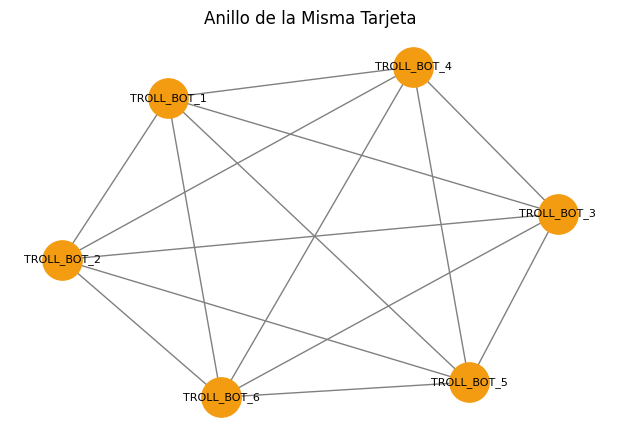

In [7]:
G_tarjeta = nx.Graph()
for origen, destino, atributos in G.edges(data=True):
    if atributos['Relacion'] == 'Misma_Tarjeta':
        G_tarjeta.add_edge(origen, destino)

componentes = list(nx.connected_components(G_tarjeta))
print(componentes)

anillo = componentes[0]
tarjeta = meta[meta['Usuario'].isin(anillo)]['Tarjeta'].unique()
print(f"Bots del anillo: {sorted(anillo)}")
print(f"Tarjeta comprometida: {tarjeta}")

plt.figure(figsize=(6,4))
nx.draw(G_tarjeta, with_labels=True, node_color='#F39C12', node_size=800, font_size=8, edge_color='gray')
plt.title('Anillo de la Misma Tarjeta')
plt.show()

**¿Cuáles son los nombres exactos (account_id) de los bots que conforman el anillo de fraude?**

Son 6 bots: TROLL_BOT_1, TROLL_BOT_2, TROLL_BOT_3, TROLL_BOT_4, TROLL_BOT_5 y TROLL_BOT_6. Habia una cuenta troll_bot_1 en minusculas pero era la misma que TROLL_BOT_1, por eso se paso todo a mayusculas antes de armar la tabla.

**¿Cuál es el Hash de la tarjeta de crédito comprometida que el equipo de soporte técnico debe bloquear ahora mismo?**

La tarjeta VISA-4455-XXXX-9090, todos los bots pagaron con esa misma tarjeta y ademas todos salen de la misma IP.

**Si tuvieran que entrenar un modelo de predicción, ¿cómo le pasarían este descubrimiento al modelo tabular (La matriz X de entrenamiento)?**

Le agregaria una columna nueva a la matriz X, por ejemplo cuantas cuentas comparten la misma tarjeta que el usuario o una columna de 0 y 1 que diga si esta dentro del anillo. El modelo tabular ve a cada usuario por separado y no sabe con quien esta conectado, entonces con esa columna le pasamos lo que encontramos en el grafo como un numero que si puede leer.